In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import tkinter as tk
from PIL import Image, ImageTk
import scipy
import slmpy
import time
from scipy.special import j1
from scipy.optimize import brentq

#From pyDMDholo
from fields import laguerre_gauss, hermite_gauss
from dmd_holograms import *
from phase_holograms import hologram_type1, hologram_type2, hologram_type3
from fourier_filter import fourier_filter
from plot_funs import colorize
from specialized_functions import plot_four

In [2]:
def slm_display(holo):
    # Check the image
    image = np.asarray(holo)

    print("Image shape:", image.shape)
    print("Image dtype:", image.dtype)
    print("Image range:", image.min(), image.max())

    # Ensure an 8-bit grayscale image
    image = np.clip(image, 0, 224).astype(np.uint8)
    pil_image = Image.fromarray(image)

    # Create display window
    root = tk.Tk()
    root.overrideredirect(True)
    root.attributes("-topmost", True)

    height, width = image.shape[:2]

    # SLM monitor position
    x, y = 1920, 0
    root.geometry(f"{width}x{height}+{x}+{y}")

    photo = ImageTk.PhotoImage(pil_image, master=root)
    label = tk.Label(root, image=photo, borderwidth=0, highlightthickness=0)
    label.image = photo
    label.pack()


    root.bind("<Escape>", lambda event: root.destroy())

    print("Window geometry:", root.geometry())
    root.mainloop()

def view_holo(holo):
    fig = plt.figure(1)

    # To access the figure manager
    manager = plt.get_current_fig_manager()

    # Set window position if supported by the backend
    if hasattr(manager, "window"):
        window = manager.window
        if hasattr(window, "wm_geometry"):  # Tkinter
            window.wm_geometry("+1200+0")
        elif hasattr(window, "setGeometry"):  # Qt
            window.setGeometry(1920, 0, 1280, 1024)

    # Remove axes margins and display the SLM
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(holo, cmap="gray", interpolation="nearest", aspect="auto")
    ax.axis("off")

    plt.show()

def make_holo(field, grating):
    # plt.imshow(np.abs(field))
    # plt.show()

    # plt.imshow(colorize(field))
    # plt.gca().axis('off')
    # plt.show()

    holo = grating(field)

    holo = holo /np.max(holo) * 224 #grayscale normalisation

    plt.imshow(holo)
    plt.show()

    return holo

1. Generating a matrix similar to the resolution of the SLM - we are using HAMAMATSU LSH0805097
Resolution: 600 x 800

In [3]:
H = 1280 #horizontal pixels - these are not the same as the camera yet so need to be changed
V = 1024 #vertical pixels

x = np.arange(-H/2,H/2-1,1)
y = np.arange(-V/2,V/2-1,1)

xv,yv = np.meshgrid(x,y) #surface area for the hologram - should be similar to that of SLMs resolution

phi = np.angle(xv + 1j * yv, deg=False) #azimuthal angle 
l = 4 #topological charge
# print(phi)
nx = 100 #number of horizontal and vertical grooves
ny = 100

gx = nx/H
gy = nx/V

# plt.plot(xv,yv, marker='o', color='r', linestyle='none')
# plt.show()

# plt.imshow(x,y)

2. Now that we have a mesh similar to the size of the SLM screen, a hologram can be encoded to it.

[[202.44669946 205.25457131 208.06223559 ...  84.98972712  87.79697484
   90.60443108]
 [206.22850036 209.03641893 211.8441297  ...  88.49940738  91.30670114
   94.11420363]
 [210.0105086  212.81847436 215.62623208 ...  92.00887844  94.81621869
   97.62376792]
 [213.7927244  216.60073781 219.40854297 ...  95.51814004  98.32552727
  101.1331237 ]
 [217.57514798 220.38320953 223.19106259 ...  99.02719197 101.83462664
  104.64227075]]


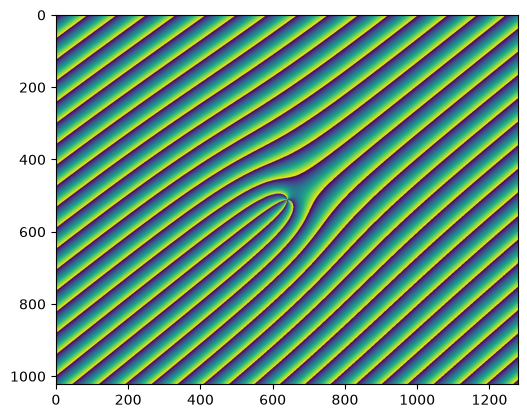

In [4]:
#1. Vortex Beam
zoom = 6
Hol_vortex = np.mod(-l*phi+2*np.pi*(gy*yv/zoom + gx*xv/zoom),2*np.pi) #if I divide the yv and xv in the formula by a factor (it zooms in to the hologram)

SLM_vortex = Hol_vortex/np.max(Hol_vortex) * 224 #grayscale normalisation

print(SLM_vortex[:5])
plt.imshow(SLM_vortex)
plt.show()

In [5]:
# 2. Laguerre gauss as an input field
N = 4
ell = 2
zoom = 200
lg = laguerre_gauss(N, ell, xv/zoom, yv/zoom)


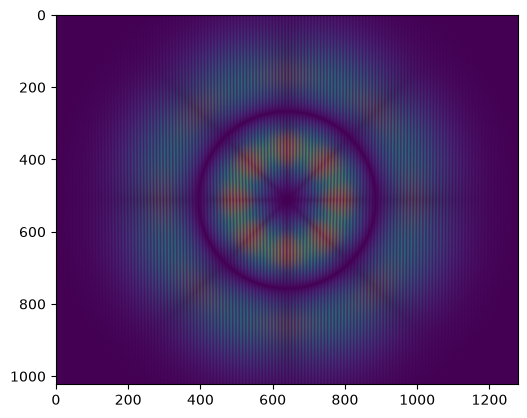

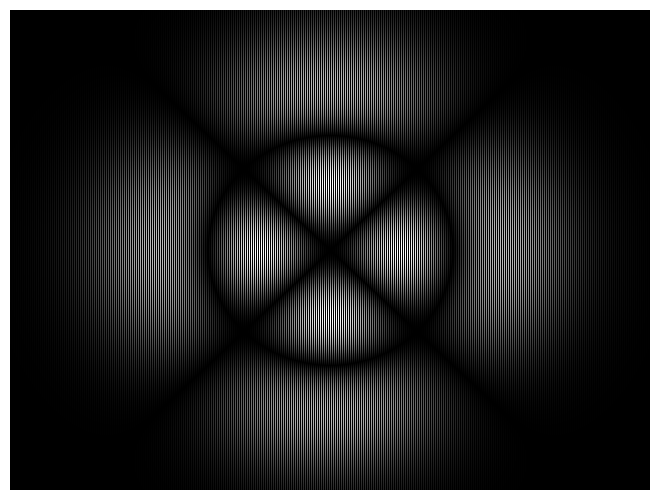

In [49]:
h1 = make_holo(lg, amplitude_lee)
view_holo(h1)

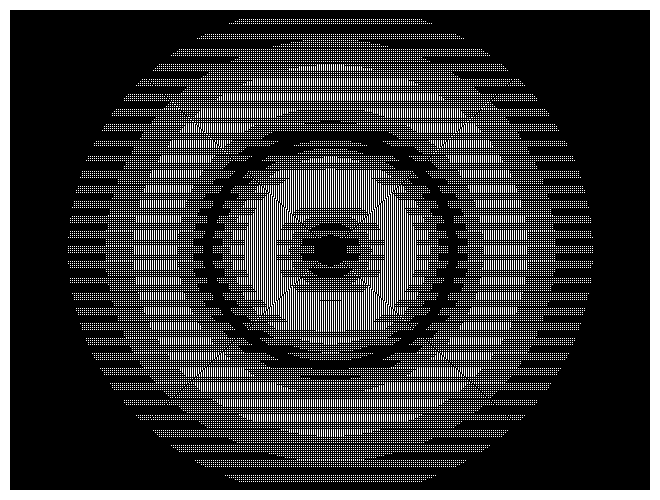

In [8]:
view_holo(lg_lee)

In [ ]:
slm_display(lg_lee)

Image shape: (1023, 1279)
Image dtype: float64
Image range: 0.0 224.0
Window geometry: 1x1+1920+0


3. Plotting the hologram on the second screen (the SLM)

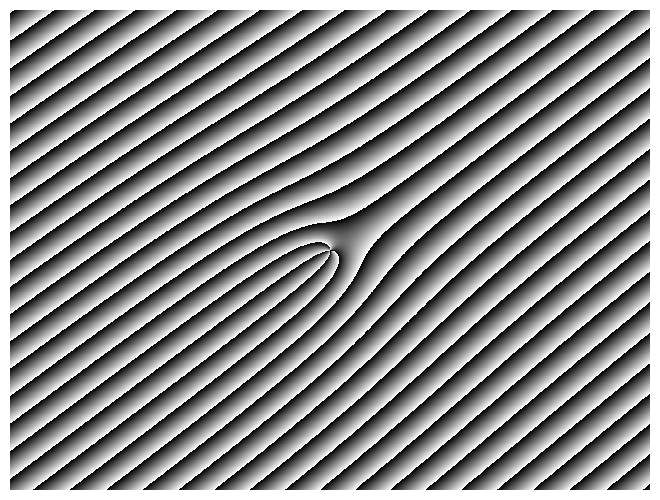

In [5]:
view_holo(SLM_vortex)

In [7]:
slm_display(SLM_vortex)

Image shape: (1023, 1279)
Image dtype: float64
Image range: 0.0 224.0
Window geometry: 1x1+1920+0


KeyboardInterrupt: 

In [ ]:
from screeninfo import get_monitors

for i, m in enumerate(get_monitors()):
    print(
        f"Monitor {i}: "
        f"x={m.x}, y={m.y}, "
        f"width={m.width}, height={m.height}"
    )

Monitor 0: x=0, y=0, width=1920, height=1080
Monitor 1: x=1920, y=0, width=1280, height=1024


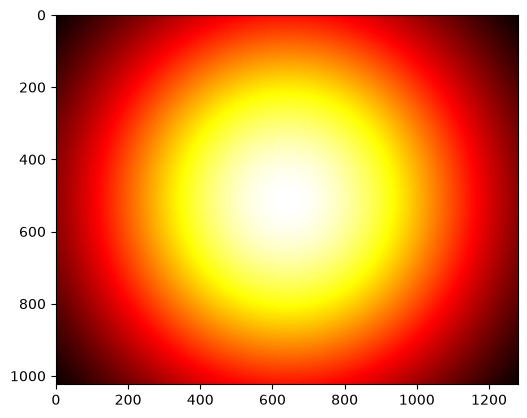

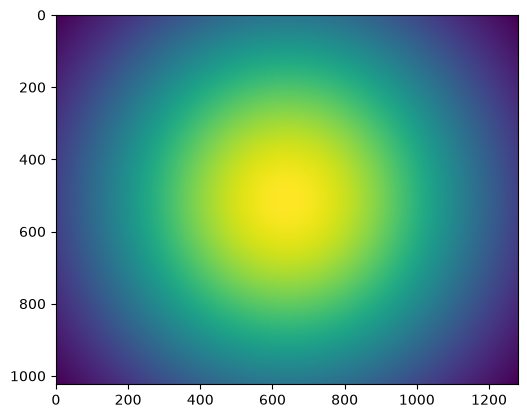

[[0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 ...
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]
 [0.         1.57079633 3.14159265 ... 1.57079633 3.14159265 4.71238898]]


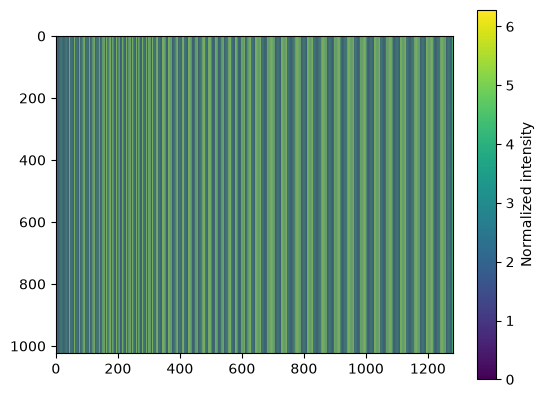

In [6]:
#Trying method 6 on a gaussian beam


Nx, Ny = 1280, 1024

# Beam center (pixels)
x0, y0 = Nx / 2, Ny / 2

w = 600

# Pixel coordinate grids
x = np.arange(Nx)
y = np.arange(Ny)
X,Y = np.meshgrid(x, y)

# Gaussian electric-field amplitude
A_rel = np.exp(-((X-x0)**2 + (Y-y0)**2) / w**2) #max amplitude is at the center 

a = 0.5

# Invert J1(f) = a * A_rel at each point
def g(f, A):
    return j1(f) - a * A

f = np.vectorize(
    lambda A: brentq(g, 0.0, 1.841183781, args=(A,))
)(A_rel)

# print(f)

# Gaussian intensity
I = A_rel**2
I2 = f**2

# Display intensity
plt.imshow(A_rel, cmap="hot", origin="upper")
plt.show()


A_norm = A_rel/np.max(A_rel) * 224

plt.imshow(A_norm)
plt.show()

#Defining phi_relg
period = 4
phi_g = 2 * np.pi * X/period
phi_des = np.zeros((Ny,Nx)) #need to check the shape cuz I had to invert

phi_relg = phi_des + phi_g
phi_relg = np.mod(phi_relg, 2*np.pi)
holo_gauss = f * phi_relg
print(phi_relg)
plt.imshow(phi_relg)
plt.colorbar(label="Normalized intensity")
plt.show()

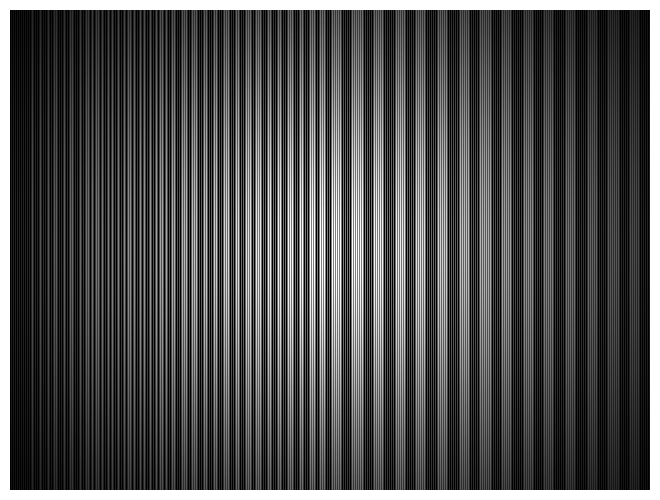

In [7]:
view_holo(holo_gauss)

In [ ]:
slm_display(holo_gauss)

Image shape: (1024, 1280)
Image dtype: float64
Image range: 0.0 7.581484822675758
Window geometry: 1x1+1920+0


In [29]:
E_out = A_rel * np.exp(1j*holo_gauss)

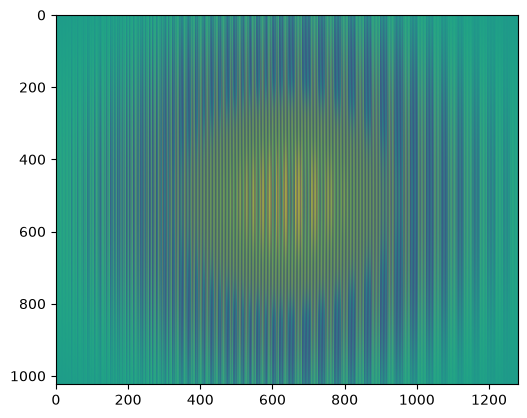

In [30]:
plt.imshow(np.real(E_out))

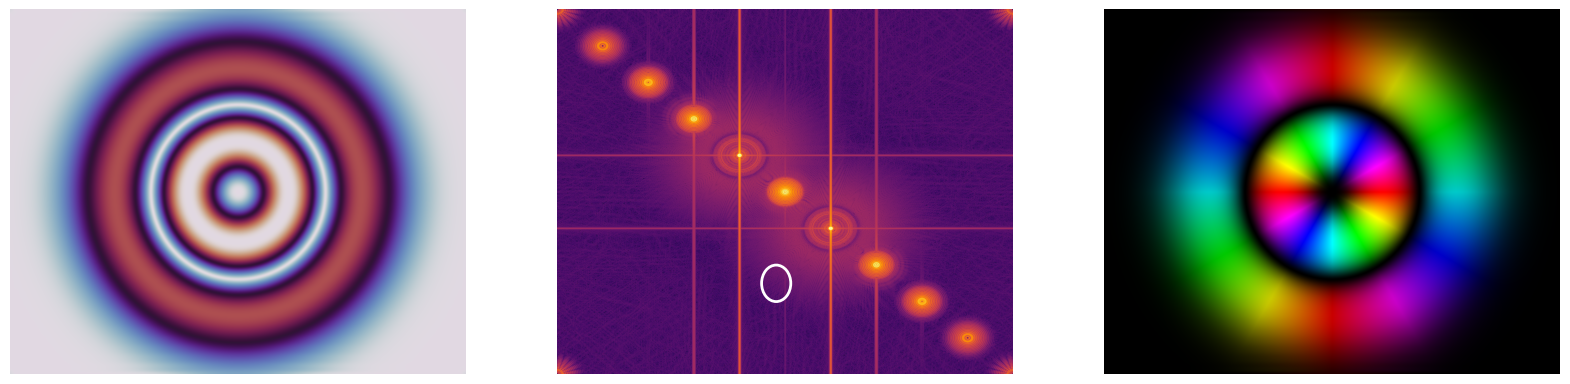

In [6]:
#Code from example_phase_hologram (Rodrigo's file)
nuvec = 0.1*np.array([1.,1.])#np.array([1/3,1/3])
SA_filter = 1/25
holo = hologram_type3(lg, nuvec, fa=None)
shaped_f, ft_holo = fourier_filter(np.exp(1j*(holo)), -nuvec, SA_filter , get_ft=True)

fig, axs = plt.subplots(1,3, figsize=(20,5))

axs[0].imshow(np.abs(shaped_f), cmap='twilight', interpolation=None)#,vmin=-np.pi/2,vmax=np.pi/2)
# plt.colorbar()
plot_four(ft_holo, ax=axs[1],  log=True, ap_rad= SA_filter, 
          ap_loc=-nuvec, vmin=-8, vmax=10.)

axs[2].imshow(colorize(shaped_f))

for i, ax in enumerate(axs.ravel()):
    ax.axis('off')

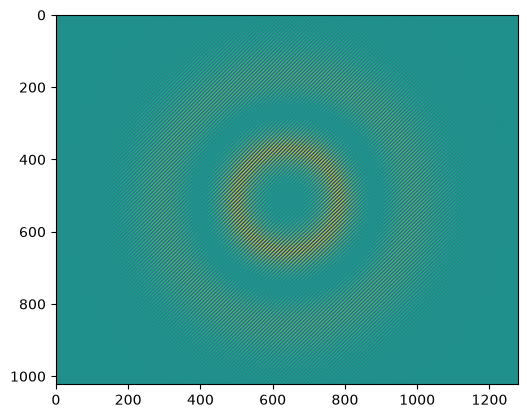

In [7]:
plt.imshow(holo)
plt.show()

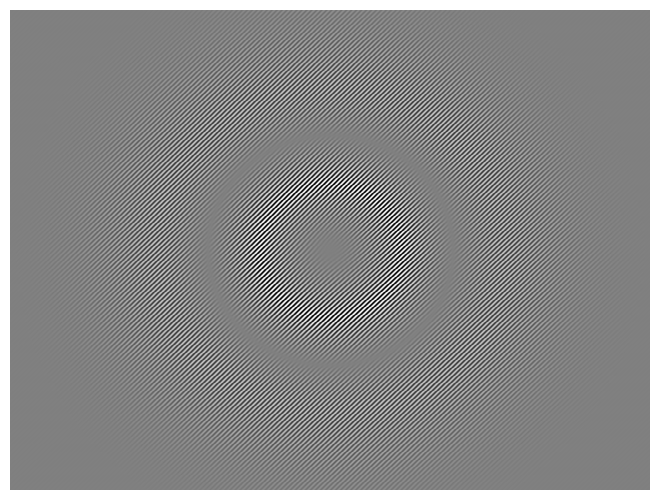

Image shape: (1023, 1279)
Image dtype: float64
Image range: 1.3706289677382921 4.912326117777699
Window geometry: 1x1+1920+0


In [ ]:
view_holo(holo)
slm_display(holo)

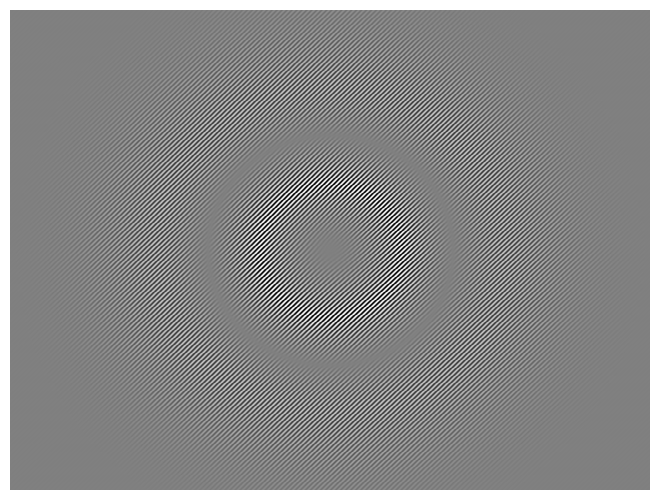

In [40]:
view_holo(holo)

In [ ]:
#Not working yet
# #For controlling the SLM
# slm = slmpy.SLMdisplay()
# resX, resY = slm.getSize() #should correspond to the resolution of the native device.

# X,Y = np.meshgrid(np.linspace(0,resX,resX),np.linspace(0,resY,resY))
# testIMG = np.round((2**8-1)*(0.5+0.5*np.sin(2*np.pi*X/50))).astype('uint8')

# slm.updateArray(testIMG)


In [42]:
# slm.close() #when finished

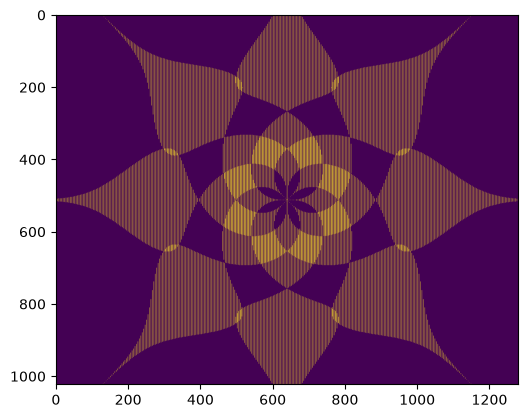

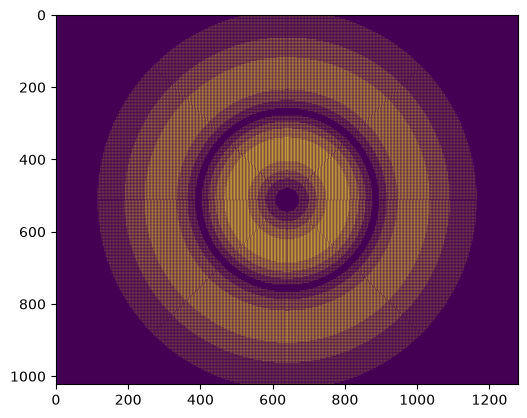

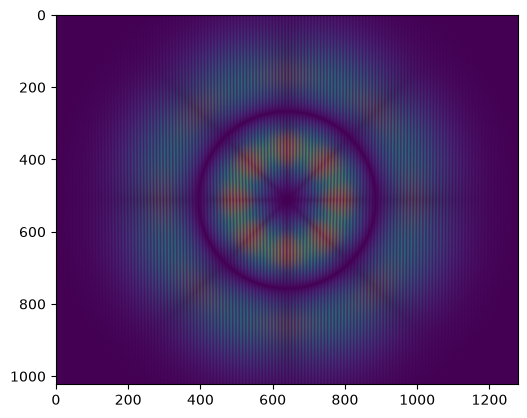

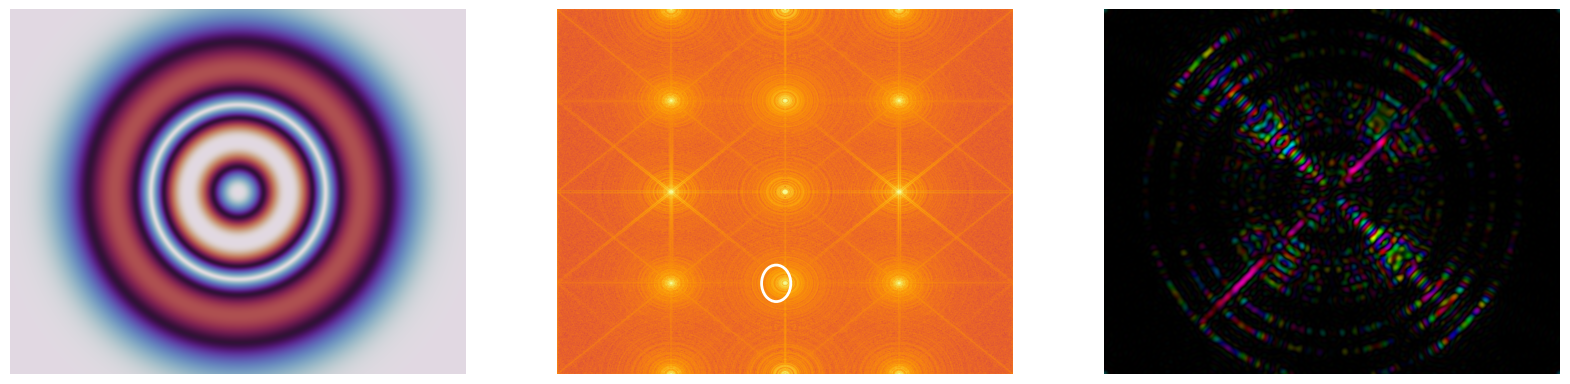

In [ ]:
#Testing with different kinds of grids
# p_lee1 = orthogonal_lee(lg, nuvec=(1/4,0))
# p_lee2 = parallel_lee(lg)
# p_lee3 = amplitude_lee(lg)
# plt.imshow(p_lee1)
# plt.show()
# plt.imshow(p_lee2)
# plt.show()
# plt.imshow(p_lee3)
# plt.show()

h1 = make_holo(lg, parallel_lee)
h2 = make_holo(lg, orthogonal_lee)
h3 = make_holo(lg, amplitude_lee)
shaped_f, ft_holo = fourier_filter(np.exp(1j*(h2)), -nuvec, SA_filter , get_ft=True)

fig, axs = plt.subplots(1,3, figsize=(20,5))

axs[0].imshow(np.abs(lg), cmap='twilight', interpolation=None)#,vmin=-np.pi/2,vmax=np.pi/2)
# plt.colorbar()
plot_four(ft_holo, ax=axs[1],  log=True, ap_rad= SA_filter, 
          ap_loc=-nuvec, vmin=-8, vmax=10.)

axs[2].imshow(colorize(shaped_f))

for i, ax in enumerate(axs.ravel()):
    ax.axis('off')

In [ ]:
slm_display(h2)

Image shape: (1023, 1279)
Image dtype: float64
Image range: 0.0 224.0
Window geometry: 1x1+1920+0


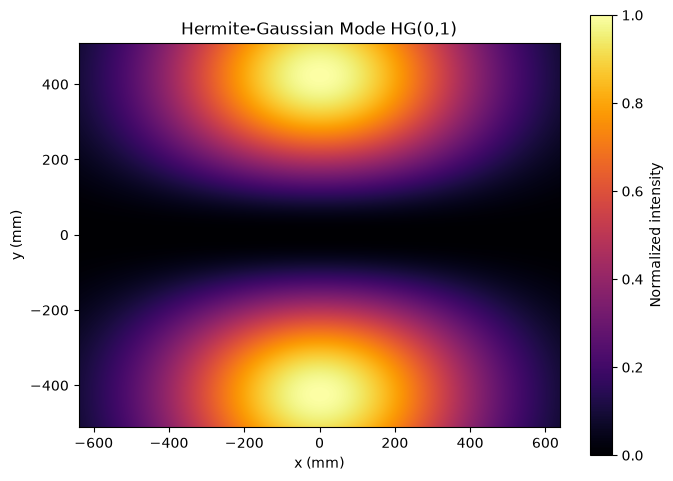

In [7]:
from scipy.special import eval_hermite, factorial

# Parameters
w0 = 600          # Beam waist (m)
wavelength = 520e-9 # Wavelength (m)
l, p = 0,1        # Hermite-Gaussian mode indices
# Normalized coordinates at beam waist
xi = np.sqrt(2) * xv / w0
eta = np.sqrt(2) * yv / w0

# Hermite-Gaussian field amplitude
H_l = eval_hermite(l, xi)
H_p = eval_hermite(p, eta)

E = (
    np.sqrt(2 / np.pi) / w0
    * H_l * H_p
    * np.exp(-(xv**2 + yv**2) / w0**2)
    / np.sqrt(2**(l+p) * factorial(l) * factorial(p))
)

# Intensity
I = np.abs(E)**2
I /= I.max()

# Plot
plt.figure(figsize=(7, 5))
plt.imshow(
    I, extent=[x.min(), x.max(),
               y.min(), y.max()],
    origin="lower", cmap="inferno", aspect="equal"
)
plt.xlabel("x (mm)")
plt.ylabel("y (mm)")
plt.title(f"Hermite-Gaussian Mode HG({l},{p})")
plt.colorbar(label="Normalized intensity")
plt.tight_layout()
plt.show()

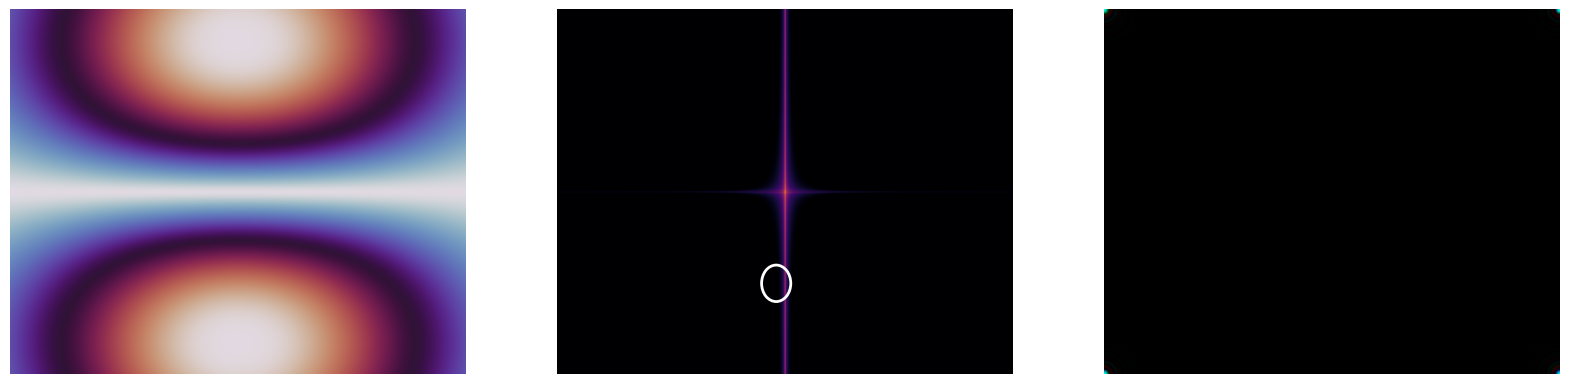

In [8]:
nuvec = 0.1*np.array([1.,1.])#np.array([1/3,1/3])
SA_filter = 1/25
holo_hg = hologram_type3(E, nuvec, fa=None)
shaped_f, ft_holo = fourier_filter(np.exp(1j*(E)), -nuvec, SA_filter , get_ft=True)

fig, axs = plt.subplots(1,3, figsize=(20,5))

axs[0].imshow(np.abs(E), cmap='twilight', interpolation=None)#,vmin=-np.pi/2,vmax=np.pi/2)
# plt.colorbar()
plot_four(ft_holo, ax=axs[1],  log=True, ap_rad= SA_filter, 
          ap_loc=-nuvec, vmin=-8, vmax=10.)

axs[2].imshow(colorize(shaped_f))

for i, ax in enumerate(axs.ravel()):
    ax.axis('off')

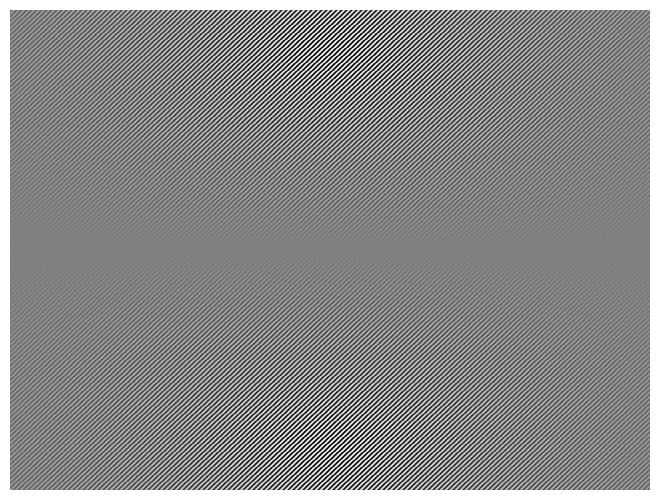

In [9]:
view_holo(holo_hg)

In [ ]:
slm_display(holo_hg)

Image shape: (1023, 1279)
Image dtype: float64
Image range: 1.457313957667587 4.825896205075693
Window geometry: 1x1+1920+0
